## Imports 

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from itertools import combinations
import holidays

SEED = 42

ruta_datos = Path("..") / "data" / "processed" / "datos_preprocess.csv"
df = pd.read_csv(ruta_datos, parse_dates=["DIA"])

Como tengo que guardar las columnas borradas así el pipeline toma las correctas, creo el json y una función para registrar.

In [62]:
import json

ruta_columnas = Path("..") / "data" / "processed" / "tratamientos_PREPROCESSING.json"
# arranca vacío en cada corrida: refleja solo los pasos que corrió esta notebook
registro_columnas = {}  

def registrar_borradas(paso, columnas):
    """Guarda en el JSON las columnas borradas en un paso (pisa el paso si ya existía).
    Si alguna columna borrada tenía tratamientos registrados, se los quita."""
    registro_columnas[paso] = sorted(columnas)
    tratamientos = registro_columnas.get("tratamientos", {})
    for col in columnas:
        tratamientos.pop(col, None)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
    print(f"{paso}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

def registrar_tratamiento(columnas, tratamiento):
    """Agrega el tratamiento a la lista de cada columna (clave 'tratamientos': {columna: [tratamientos en orden]}).
    Si la columna ya tiene ese tratamiento no lo repite (por si se vuelve a correr la celda)."""
    tratamientos = registro_columnas.setdefault("tratamientos", {})
    for col in columnas:
        lista = tratamientos.setdefault(col, [])
        if tratamiento not in lista:
            lista.append(tratamiento)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
    print(f"{tratamiento}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

El tratamiento de valores nulos, de valores negativos y de columnas idénticas o en 0 se hace en `eda.ipynb` (queda registrado en `tratamiento_columnas_eda.json`). El CSV que lee esta notebook ya tiene que venir con esos pasos aplicados.

## Split Test/Train

In [63]:
df_sin_ident = df.sort_values("DIA").reset_index(drop=True)
n_eval = round(len(df_sin_ident) * 0.15)   # días de validación y de test

# Con test_size fijo y 2 cortes, TimeSeriesSplit da:
#   corte 1: train = lo más antiguo (70 %)      | evaluación = los 15 % siguientes (validación)
#   corte 2: train = train + validación (85 %)  | evaluación = el 15 % más reciente (test)
(idx_train, idx_val), (_, idx_test) = TimeSeriesSplit(n_splits=2, test_size=n_eval).split(df_sin_ident)
es_train = df_sin_ident.index.isin(idx_train)   # máscara para calcular los límites de outliers solo con train

for nombre, idx in [("Train", idx_train), ("Validación", idx_val), ("Test", idx_test)]:
    dias = df_sin_ident.loc[idx, "DIA"]
    print(f"{nombre:<11} {len(idx):>4} días ({len(idx) / len(df_sin_ident):.1%}) | {dias.min().date()} -> {dias.max().date()}")

# Se guardan los cortes para que el modelado y el pipeline usen exactamente los mismos
registro_columnas["split"] = {nombre: str(df_sin_ident.loc[idx, "DIA"].max().date())
                              for nombre, idx in [("fin_train", idx_train), ("fin_val", idx_val)]}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")

Train        846 días (69.9%) | 2020-07-04 -> 2022-10-27
Validación   182 días (15.0%) | 2022-10-28 -> 2023-04-27
Test         182 días (15.0%) | 2023-04-28 -> 2023-10-26


79

## Outliers

Voy a usar Z-Score para obtenerlos. Mi idea es poner umbrales grandes de outliers, por que estoy trabajando con 350 columnas y no voy a poder usar LOF (mucha dimensionalidad). 

Entonces, mi plan es usar Z-Score para sacar los ruidos muy molestos, y voy a usar transformaciones más tarde para llevar todo a una escala más trabajable.

In [64]:
UMBRAL_Z = 10   #  el estándar es 3.5, agarro 10 para que salten los más altos nada más

In [65]:
def outliers_zscore(datos, umbral=3, excluir=(), filas_ref=None, col_fecha="DIA"):
    """Z-score clásico por columna: |x - media| / desvío > umbral.

    La media y el desvío se calculan solo con las filas de `filas_ref` (máscara booleana, por ejemplo train)
    y se aplican a todas las filas. Si es None, usa todas.
    Ignora columnas binarias (en las filas de referencia) y las de `excluir`.
    Devuelve: tabla por columna (ordenada por z máx) y máscara de outliers (días x columnas).
    """
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x if filas_ref is None else x.loc[filas_ref]
    x = x.loc[:, ref.nunique() > 2]
    ref = ref[x.columns]

    z = ((x - ref.mean()) / ref.std()).abs()
    es_out = z > umbral

    fila_max = z.idxmax()
    tabla = pd.DataFrame({
        "n outliers": es_out.sum(),
        "z máx": z.max().round(1),
        "día z máx": datos.loc[fila_max, col_fecha].dt.date.to_numpy(),
        "valor z máx": [x.at[i, c] for c, i in fila_max.items()],
        "mediana": ref.median(),
    })
    tabla = tabla[tabla["n outliers"] > 0].sort_values("z máx", ascending=False)
    return tabla, es_out


def winsorizar_marcados(datos, mascara, p_inf=0.02, p_sup=0.98, filas_ref=None,
                        frio="Consolidado EE | Frio (Kw)", col_fecha="DIA"):
    """Lleva al percentil p_inf/p_sup de su columna SOLO las celdas marcadas en `mascara`.

    Los percentiles se calculan solo con las filas de `filas_ref` (si es None, con todas).
    El resto de la columna no se toca. Si se corrige Frio, recalcula el target (Frio de D+1).
    Devuelve el df corregido y la lista de columnas modificadas.
    """
    cols = list(mascara.columns[mascara.any()])
    x = datos[cols]
    ref = x if filas_ref is None else x.loc[filas_ref]
    recortado = x.clip(lower=ref.quantile(p_inf), upper=ref.quantile(p_sup), axis=1)

    df = datos.copy()
    df[cols] = x.where(~mascara[cols], recortado)

    if frio in cols:
        frio_nuevo = df.set_index(col_fecha)[frio]
        df["target"] = (df[col_fecha] + pd.Timedelta(days=1)).map(frio_nuevo).fillna(df["target"])
    return df, cols

Voy a hacer dos pasadas de z-score con un umbral muy alto. 

Mi idea es que el primer umbral alto tome los valores como el de frío, que tien 3 outliers muy grandes (y lo mismo para el resto de columnas). El segundo es el que va a trabajar con los outliers un poco más chicos que quedaron.

In [66]:
c_frio = "Consolidado EE | Frio (Kw)"
# Fuera del análisis: calendario (codificado a propósito), metas (rellenadas con 1 provisoriamente)
# y target (es Frio corrido un día: se corrige Frio y se recalcula)
calendario = [c for c in df_sin_ident.columns
              if c in ("DIA_SEMANA", "MES", "ESTACION", "FIN_SEMANA") or c.endswith(("_sin", "_cos"))]
metas = [c for c in df_sin_ident.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
excluir_z = ["target", *calendario, *[c for c in metas if c in df_sin_ident.columns]]

tabla_z1, mascara_z1 = outliers_zscore(df_sin_ident, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out1, cols_out1 = winsorizar_marcados(df_sin_ident, mascara_z1, filas_ref=es_train)

print(f"Pasada 1 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z1.sum().sum()} en {len(cols_out1)} columnas")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z1.head(10))

print(f"Frio corregido en {mascara_z1[c_frio].sum()} días; target máximo: {df_out1['target'].max():,.0f}")

registrar_tratamiento(cols_out1, "winsor_p2_p98_si_zscore_pasada1")

Pasada 1 | umbral 10 | valores corregidos: 163 en 64 columnas


,n outliers,z máx,día z máx,valor z máx,mediana
Totalizadores Energia | KW Enfluentes Coc,4,"3,054.50",2023-06-28,"125,244.00",107.50
Consolidado EE | Efluentes (Kw),3,589.90,2023-06-28,"125,882.00",861.00
Consolidado KPI | ET Linea 4/Hl,11,68.50,2023-02-27,500.03,6.38
Totalizadores Produccion | Hl Mosto Bieckert Urbana,3,40.00,2023-07-22,"2,432.00",0.00
Consolidado KPI | CO 2 Filtro / Hl,1,33.90,2023-09-16,6.00,0.42
Consolidado KPI | Agua Linea 4/Hl,8,32.80,2023-07-31,35.67,0.34
Consolidado EE | Frio (Kw),1,29.00,2021-05-03,"5,572,801.00","25,626.00"
Totalizadores Agua | FC Linea 3,1,28.60,2022-06-27,"13,264.10",112.75
Consolidado KPI | Aire L4 / Hl,4,28.40,2023-06-19,57.37,0.64
Totalizadores Energia | KW Caldera 3,1,28.40,2021-09-25,"65,593.00",80.00


Frio corregido en 1 días; target máximo: 56,128
winsor_p2_p98_si_zscore_pasada1: 64 columnas registradas en tratamientos_PREPROCESSING.json


In [67]:
tabla_z2, mascara_z2 = outliers_zscore(df_out1, umbral=UMBRAL_Z, excluir=excluir_z, filas_ref=es_train)
df_out2, cols_out2 = winsorizar_marcados(df_out1, mascara_z2, filas_ref=es_train)

print(f"Pasada 2 | umbral {UMBRAL_Z} | valores corregidos: {mascara_z2.sum().sum()} en {len(cols_out2)} columnas "
      f"(train: {mascara_z2[es_train].sum().sum()} | validación + test: {mascara_z2[~es_train].sum().sum()})")
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:,.2f}".format):
    display(tabla_z2.head(10))

registrar_tratamiento(cols_out2, "winsor_p2_p98_si_zscore_pasada2")

Pasada 2 | umbral 10 | valores corregidos: 93 en 38 columnas (train: 66 | validación + test: 27)


,n outliers,z máx,día z máx,valor z máx,mediana
Consolidado KPI | EE Cocina / Hl,3,34.90,2023-08-10,7.76,0.29
Consolidado KPI | EE Frio / Hl,1,28.60,2020-07-04,333.14,2.62
Totalizadores Energia | KW Caldera 3,1,28.60,2021-09-24,"14,451.00",80.00
Consolidado KPI | Agua Linea 4/Hl,7,27.40,2023-07-24,10.45,0.34
Consolidado KPI | EE Elaboracion / Hl,1,27.20,2020-07-04,47.15,0.76
Consolidado KPI | EE CO2 / Hl,1,25.70,2021-10-30,10.09,0.18
Consolidado KPI | ET Linea 3/Hl,1,24.80,2021-03-09,437.18,13.68
Consolidado KPI | ET Planta / Hl,1,24.20,2021-12-18,"1,519.92",59.55
Consolidado KPI | Agua Linea 3/Hl,1,22.90,2021-03-09,50.91,1.21
Consolidado KPI | Agua Cocina / Hl,2,22.70,2021-07-21,24.23,1.42


winsor_p2_p98_si_zscore_pasada2: 38 columnas registradas en tratamientos_PREPROCESSING.json


Registro en el json los valores así el pipeline lo reproduce bien.

In [68]:
def parametros_zscore(datos, excluir, filas_ref, p_inf=0.02, p_sup=0.98, col_fecha="DIA"):
    """Media, desvío y percentiles de train de las mismas columnas que analiza outliers_zscore
    (numéricas, no excluidas, con más de 2 valores distintos en train), para aplicarlos en predict.py."""
    x = datos.drop(columns=[col_fecha, *excluir]).select_dtypes("number")
    ref = x.loc[filas_ref]
    ref = ref.loc[:, ref.nunique() > 2]
    return {nombre: {c: float(v) for c, v in serie.items()}
            for nombre, serie in [("media", ref.mean()), ("desvio", ref.std()),
                                  ("p_inf", ref.quantile(p_inf)), ("p_sup", ref.quantile(p_sup))]}

registro_columnas["outliers"] = {
    "umbral": UMBRAL_Z,
    "excluir": excluir_z,
    "pasada1": parametros_zscore(df_sin_ident, excluir_z, es_train),
    "pasada2": parametros_zscore(df_out1, excluir_z, es_train),
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
print(f"Outliers registrados: pasada 1 {len(registro_columnas['outliers']['pasada1']['media'])} columnas | "
      f"pasada 2 {len(registro_columnas['outliers']['pasada2']['media'])} columnas")

Outliers registrados: pasada 1 147 columnas | pasada 2 145 columnas


Aplico para el test y validación:

In [69]:
df_train = df_out2.loc[idx_train].reset_index(drop=True)
df_val = df_out2.loc[idx_val].reset_index(drop=True)
df_test = df_out2.loc[idx_test].reset_index(drop=True)

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape}")

Train       (846, 208)
Validación  (182, 208)
Test        (182, 208)


## Feature Engineering

### Temperatura

Voy a usar a  open meteo para tomar los datos; planta esta en Tecate, Baja California.

In [70]:
from urllib.parse import urlencode
from urllib.request import urlopen


def descargar_temperatura(desde, hasta, ruta):
    """Baja de Open-Meteo la temperatura diaria de Tecate y la guarda en un CSV."""
    parametros = {
        "latitude": 32.5667,      # Tecate, Baja California
        "longitude": -116.6333,
        "start_date": desde,
        "end_date": hasta,
        "daily": "temperature_2m_mean,temperature_2m_max,temperature_2m_min",
        "timezone": "America/Tijuana",
    }
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(parametros)
    with urlopen(url, timeout=60) as respuesta:
        diario = json.load(respuesta)["daily"]

    temp = pd.DataFrame({
        "DIA": pd.to_datetime(diario["time"]),
        "TEMP_media": diario["temperature_2m_mean"],
        "TEMP_max": diario["temperature_2m_max"],
        "TEMP_min": diario["temperature_2m_min"],
    })
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temp.to_csv(ruta, index=False, lineterminator="\n")
    return temp

In [71]:
ruta_temp = Path("..") / "data" / "external" / "temperatura_tecate.csv"
if ruta_temp.exists():
    temp = pd.read_csv(ruta_temp, parse_dates=["DIA"])
else:
    hasta = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")
    temp = descargar_temperatura("2020-06-01", hasta, ruta_temp)

print(f"Temperatura: {temp.shape} | {temp['DIA'].min().date()} -> {temp['DIA'].max().date()} "
      f"| nulos: {temp.isna().sum().sum()}")

Temperatura: (2351, 4) | 2020-06-01 -> 2026-11-07 | nulos: 0


Anda bien. Agrego las columnas: 

1 - La temperatura (que viene con la media del día, la mínima, máxima, y su diferencial comparado al día anterior).

In [72]:
def agregar_temperatura(datos, temp, col_fecha="DIA"):
    """Pega la temperatura del día D y su variación contra el día anterior (> 0: está subiendo).
    La variación se calcula sobre la tabla de temperatura (calendario continuo),
    así que funciona igual en cualquier conjunto aunque se procese por separado."""
    temp = temp.sort_values(col_fecha).copy()
    temp["TEMP_dif"] = temp["TEMP_media"].diff()
    return datos.merge(temp, on=col_fecha, how="left", validate="m:1")


In [73]:
df_train = agregar_temperatura(df_train, temp)
df_val = agregar_temperatura(df_val, temp)
df_test = agregar_temperatura(df_test, temp)

cols_temp = ["TEMP_media", "TEMP_max", "TEMP_min", "TEMP_dif"]
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | días sin temperatura: {d[cols_temp].isna().any(axis=1).sum()}")

Train       (846, 212) | días sin temperatura: 0
Validación  (182, 212) | días sin temperatura: 0
Test        (182, 212) | días sin temperatura: 0


2 - Tomo la media del frío de los últimos 5 días (y la derivada). 

In [74]:
def serie_con_previo(datos, columna, previo=None, col_fecha="DIA"):
    """Serie de `columna` indexada por fecha, con los días de `previo` adelante (si se pasa)."""
    partes = [datos[[col_fecha, columna]]] if previo is None else [previo[[col_fecha, columna]], datos[[col_fecha, columna]]]
    return pd.concat(partes).sort_values(col_fecha).set_index(col_fecha)[columna]


def media_movil(datos, columna, nombre, ventana, previo=None, col_fecha="DIA"):
    """Promedio de los últimos `ventana` días, incluyendo el día D (no usa datos futuros).
    `previo`: días anteriores a `datos`, para que los primeros días tengan historia."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).rolling(ventana, min_periods=1).mean()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos


def variacion(datos, columna, nombre, previo=None, col_fecha="DIA"):
    """Diferencia contra el día anterior (> 0: está creciendo).
    Si no hay día anterior (inicio de la serie, sin `previo`), queda en 0."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).diff().fillna(0)
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [75]:
# 1) Media de frío de los últimos 5 días (D-4 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media5", ventana=5)
df_val = media_movil(df_val, c_frio, "FRIO_media5", ventana=5, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media5", ventana=5, previo=pd.concat([df_train, df_val]))

# 2) Su variación: la historia tiene que tener FRIO_media5, por eso va después del paso 1
df_train = variacion(df_train, "FRIO_media5", "FRIO_media5_dif")
df_val = variacion(df_val, "FRIO_media5", "FRIO_media5_dif", previo=df_train)
df_test = variacion(df_test, "FRIO_media5", "FRIO_media5_dif", previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[['FRIO_media5', 'FRIO_media5_dif']].isna().sum().sum()}")

Train       (846, 214) | nulos nuevos: 0
Validación  (182, 214) | nulos nuevos: 0
Test        (182, 214) | nulos nuevos: 0


3 - Tomo la media del frío para los últimos 14 días. 

In [76]:
# Media de frío de los últimos 14 días (D-13 a D)
df_train = media_movil(df_train, c_frio, "FRIO_media14", ventana=14)
df_val = media_movil(df_val, c_frio, "FRIO_media14", ventana=14, previo=df_train)
df_test = media_movil(df_test, c_frio, "FRIO_media14", ventana=14, previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d['FRIO_media14'].isna().sum()}")

Train       (846, 215) | nulos nuevos: 0
Validación  (182, 215) | nulos nuevos: 0
Test        (182, 215) | nulos nuevos: 0


4 - Como del EDA se que el día si importa, tomo el promedio del frío del mismo día de la semana en las últimas 4 semanas.

In [77]:
def media_mismo_dia(datos, columna, nombre, semanas, previo=None, col_fecha="DIA"):
    """Promedio de `columna` en los últimos `semanas` días con el mismo día de la semana que D+1
    (D-6, D-13, D-20, ...). Al inicio de la serie promedia los que haya; si no hay ninguno,
    usa el primer valor disponible (como rezago)."""
    serie = serie_con_previo(datos, columna, previo, col_fecha)
    mismos_dias = pd.concat([serie.shift(6 + 7 * s) for s in range(semanas)], axis=1)
    resultado = mismos_dias.mean(axis=1).bfill()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [78]:
df_train = media_mismo_dia(df_train, c_frio, "FRIO_mismo_dia4", semanas=4)
df_val = media_mismo_dia(df_val, c_frio, "FRIO_mismo_dia4", semanas=4, previo=df_train)
df_test = media_mismo_dia(df_test, c_frio, "FRIO_mismo_dia4", semanas=4, previo=pd.concat([df_train, df_val]))

for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d['FRIO_mismo_dia4'].isna().sum()}")

Train       (846, 216) | nulos nuevos: 0
Validación  (182, 216) | nulos nuevos: 0
Test        (182, 216) | nulos nuevos: 0


### Producción

Viendo las columnas de consolidado producción:

In [79]:
[c for c in df_train.columns if c.startswith("Consolidado Produccion")]

['Consolidado Produccion | Hl de Mosto',
 'Consolidado Produccion | Hl Cerveza Cocina',
 'Consolidado Produccion | Hl Producido Bodega',
 'Consolidado Produccion | Hl Cerveza Filtrada',
 'Consolidado Produccion | Hl Cerveza Envasada',
 'Consolidado Produccion | Hl Cerveza L2',
 'Consolidado Produccion | Hl Cerveza L3',
 'Consolidado Produccion | Hl Cerveza L4',
 'Consolidado Produccion | Hl Cerveza L5']

Despues de buscar como funciona la cadena de producción de la cerveza, lo resumo en esto: 

- Molís, filtras, y hervís para llegar al mosto. Despues de hervirlo, se tiene que enfriar rapidamente para que no se arruine. 
    - Aca trabaja HL de Mosto, HL Cerveza Cocina.
- Dejas el mosto fermentando. Fermentar a su vez causa calor, por lo tanto hay que seguir enfriando para que no se arruine. Participa ahí Hl Producido Bodega.
- Se tiene que filtrar la cerveza a 0 grados 'para que no se enturbie', y los tanques de cerveza filtrada también quedan fríos. Trabaja Hl Cerveza Filtrada.
- Envasado son 4 líneas de producción, HL Cerveza Ln y su consolidado de Hl Cerveza envasada.


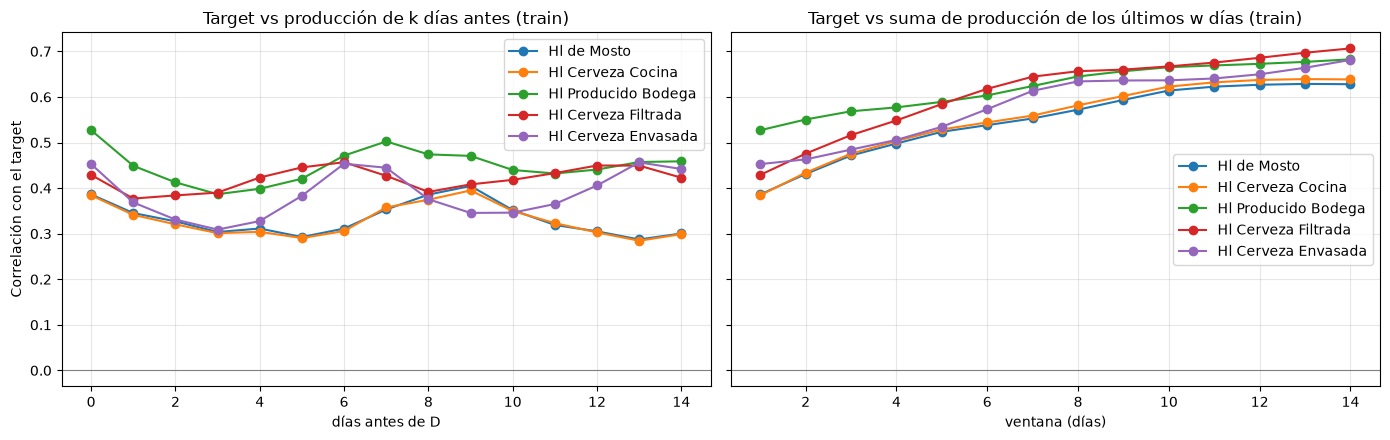

In [80]:
cols_prod = [
    "Consolidado Produccion | Hl de Mosto",
    "Consolidado Produccion | Hl Cerveza Cocina",
    "Consolidado Produccion | Hl Producido Bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada",
]
faltan = [c for c in cols_prod if c not in df_train.columns]
print("No están en el df:", faltan) if faltan else None
cols_prod = [c for c in cols_prod if c in df_train.columns]

tr = df_train.sort_values("DIA")
rezagos = range(0, 15)
corto = {c: c.split(" | ", 1)[-1] for c in cols_prod}

# Correlación del target con la producción de k días antes de D
corr_rezago = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].shift(k)) for k in rezagos] for c in cols_prod},
                           index=pd.Index(rezagos, name="días antes de D"))

# Correlación del target con la suma de producción de los últimos w días (D-w+1 a D)
ventanas = range(1, 15)
corr_suma = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].rolling(w).sum()) for w in ventanas] for c in cols_prod},
                         index=pd.Index(ventanas, name="ventana (días)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
corr_rezago.plot(ax=axes[0], marker="o", title="Target vs producción de k días antes (train)")
corr_suma.plot(ax=axes[1], marker="o", title="Target vs suma de producción de los últimos w días (train)")
axes[0].set_ylabel("Correlación con el target")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

En el eje Y la correlación con frío, y en el eje X cuantos días tiene de diferencia con 0. 
Viendo el primer grafico, nos damos cuenta que el HL de cerveza envasada hace el pico a los 7 días, y despues vuelve a repetir el patrón. 

Hay un cambio semanal en la producción entonces. Bodega es la que más correlación tiene en el mismo día, y aumenta mucho la correlación para cerveza envasada y filtrada en el día 7. 

Con esto, conozco que hay una demora entre cada proceso y uso eso para crear las features: 
- Hago columnas que sean la producción hace 7 días para producido bodega y cerveza envasada. Filtrada ocurre un día antes, pero voy a mantenerlo en 7 por continuidad. 
- Para Cocina y mosto, parece que toma el valor máximo a los 9 días, así qeu las hago con esas. 

Aparte, le voy a hacer derivadas a los 4 sectores (a cocina y mosto no le hago uno por separado por que son iguales).

In [81]:
def rezago(datos, columna, nombre, k, previo=None, col_fecha="DIA"):
    """Valor de `columna` k días antes de D. Con `previo`, los primeros días toman la historia.
    Si no hay k días anteriores (inicio de la serie), usa el primer valor disponible."""
    resultado = serie_con_previo(datos, columna, previo, col_fecha).shift(k).bfill()
    datos = datos.copy()
    datos[nombre] = datos[col_fecha].map(resultado)
    return datos

In [82]:
# {columna: (sector, días de rezago)}
rezagos_prod = {
    "Consolidado Produccion | Hl de Mosto": ("mosto", 9),
    "Consolidado Produccion | Hl Cerveza Cocina": ("cocina", 9),
    "Consolidado Produccion | Hl Producido Bodega": ("bodega", 7),
    "Consolidado Produccion | Hl Cerveza Filtrada": ("filtrada", 7),
    "Consolidado Produccion | Hl Cerveza Envasada": ("envasada", 7),
}
# {columna: sector} para las derivadas (una por sector)
derivadas_prod = {
    "Consolidado Produccion | Hl Cerveza Cocina": "cocina",
    "Consolidado Produccion | Hl Producido Bodega": "bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada": "filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada": "envasada",
}


In [83]:
faltan = [c for c in {**rezagos_prod, **derivadas_prod, c_frio: None} if c not in df_train.columns]
assert not faltan, f"No están en el df: {faltan}"

nuevas = []
for col, (sector, k) in rezagos_prod.items():
    nombre = f"PROD_{sector}_lag{k}"
    df_train = rezago(df_train, col, nombre, k)
    df_val = rezago(df_val, col, nombre, k, previo=df_train)
    df_test = rezago(df_test, col, nombre, k, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

for col, sector in derivadas_prod.items():
    nombre = f"PROD_{sector}_dif"
    df_train = variacion(df_train, col, nombre)
    df_val = variacion(df_val, col, nombre, previo=df_train)
    df_test = variacion(df_test, col, nombre, previo=pd.concat([df_train, df_val]))
    nuevas.append(nombre)

# Frío del mismo día de la semana que D+1, una semana antes (D - 6)
df_train = rezago(df_train, c_frio, "FRIO_lag6", 6)
df_val = rezago(df_val, c_frio, "FRIO_lag6", 6, previo=df_train)
df_test = rezago(df_test, c_frio, "FRIO_lag6", 6, previo=pd.concat([df_train, df_val]))
nuevas.append("FRIO_lag6")

print(f"Columnas nuevas: {len(nuevas)}")
for nombre, d in [("Train", df_train), ("Validación", df_val), ("Test", df_test)]:
    print(f"{nombre:<11} {d.shape} | nulos nuevos: {d[nuevas].isna().sum().sum()}")
print(f"Corr con target (train): FRIO_lag6 {df_train['FRIO_lag6'].corr(df_train['target']):.3f} | "
      f"Frio de D {df_train[c_frio].corr(df_train['target']):.3f}")

Columnas nuevas: 10
Train       (846, 226) | nulos nuevos: 0
Validación  (182, 226) | nulos nuevos: 0
Test        (182, 226) | nulos nuevos: 0
Corr con target (train): FRIO_lag6 0.728 | Frio de D 0.839


### Ratios de Producción

Se sugieren ratios de producción, pero como no encuentro una buena relación base para armarlos a mano, lo que voy a hacer es armar una columna de ratio para cada parte de producción: (Zona_Producción / Frio). 

La idea es que te diga cuantos Hl de cada etapa pasan por cada Kw de frío, entonces al modelo le da una relación entre Kw y Hl. Ya existen relaciones parecidas en las columnas, pero las voy a dejar y en todo caso los selectores las sacan.

In [84]:
def agregar_combinaciones(datos, ratios=None, interacciones=None):
    """Agrega columnas calculadas con valores del mismo día (no ajusta nada con train, no necesita `previo`).
    ratios: {nombre: (numerador, denominador)} -> numerador / denominador (0 si el denominador es 0).
    interacciones: {nombre: (col_a, col_b)} -> col_a * col_b."""
    ratios, interacciones = ratios or {}, interacciones or {}
    nuevas = {}
    for nombre, (num, den) in ratios.items():
        nuevas[nombre] = (datos[num] / datos[den]).where(datos[den] != 0, 0)
    for nombre, (a, b) in interacciones.items():
        nuevas[nombre] = datos[a] * datos[b]
    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1)

In [85]:
# Hl de cada columna de producción por kW de frío del día (producción / frío: el frío nunca es 0)
cols_prod_ratio = [c for c in df_train.columns if c.startswith("Consolidado Produccion")]

def sector_de(col):
    """'Consolidado Produccion | Hl Producido Bodega' -> 'bodega'; 'Hl Cerveza L2' -> 'l2'."""
    nombre = re.sub(r"\b(Hl|Cerveza|Producido|de)\b", "", col.split(" | ", 1)[-1])
    return "_".join(nombre.lower().split())

ratios_prod = {f"RATIO_{sector_de(c)}_frio": (c, c_frio) for c in cols_prod_ratio}

df_train = agregar_combinaciones(df_train, ratios=ratios_prod)
df_val = agregar_combinaciones(df_val, ratios=ratios_prod)
df_test = agregar_combinaciones(df_test, ratios=ratios_prod)

corr = df_train[list(ratios_prod)].corrwith(df_train["target"]).round(3)
print(f"Columnas nuevas: {len(ratios_prod)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")
print("Corr con target (train):", corr.to_dict())

Columnas nuevas: 9 | shapes: train (846, 235), val (182, 235), test (182, 235)
Corr con target (train): {'RATIO_mosto_frio': -0.192, 'RATIO_cocina_frio': -0.157, 'RATIO_bodega_frio': -0.307, 'RATIO_filtrada_frio': -0.283, 'RATIO_envasada_frio': -0.277, 'RATIO_l2_frio': -0.154, 'RATIO_l3_frio': -0.179, 'RATIO_l4_frio': -0.235, 'RATIO_l5_frio': 0.003}


### Eficiencia en producción 

Ya lo habia comentado en los valores nulos, están las columnas de meta vinculadas a la producción del KPI. Mi plan es tomar la feature recomendada, eficiencia energética que es consumo Hl/meta. 

In [86]:
def agregar_eficiencias(datos, medias=None):
    """Crea efic_<X> = (X / Hl) / (Meta X) para cada meta que tiene su KPI.
    Solo en días con meta (no_hay_meta == 0); el resto lleva la media de train.
    Con medias=None (train) las calcula; si no, aplica las recibidas. Devuelve (datos, medias)."""
    # 'Meta EE Planta' y 'EE Planta / Hl' -> 'eeplanta' (sin hoja, sin 'Meta', sin '/Hl', sin espacios)
    clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
    kpis = {clave(c): c for c in datos.columns if c.lower().replace(" ", "").endswith("/hl")}
    metas = [c for c in datos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

    calcular = medias is None
    medias = {} if calcular else medias
    nuevas = {}
    for meta in metas:
        kpi = kpis.get(clave(meta))
        if kpi is None:
            continue
        nombre = "efic_" + kpi.split(" | ", 1)[-1].split("/")[0].strip()
        efic = (datos[kpi] / datos[meta]).where(datos["no_hay_meta"].eq(0) & datos[meta].ne(0))
        if calcular:
            medias[nombre] = float(efic.mean())
        nuevas[nombre] = efic.fillna(medias[nombre])

    datos = datos.drop(columns=list(nuevas), errors="ignore")   # si se vuelve a correr, no duplica
    return pd.concat([datos, pd.DataFrame(nuevas, index=datos.index)], axis=1), medias

In [87]:
df_train, medias_efic = agregar_eficiencias(df_train)
df_val, _ = agregar_eficiencias(df_val, medias_efic)
df_test, _ = agregar_eficiencias(df_test, medias_efic)

registro_columnas["medias_train"] = {"eficiencias": medias_efic}
registrar_tratamiento(list(medias_efic), "media_train_si_no_hay_meta")
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")

n_metas = sum(c.split(" | ", 1)[-1].strip().lower().startswith("meta") for c in df_train.columns)
print(f"Eficiencias creadas: {len(medias_efic)} de {n_metas} metas")
print(f"Shapes: train {df_train.shape} | val {df_val.shape} | test {df_test.shape}")

media_train_si_no_hay_meta: 33 columnas registradas en tratamientos_PREPROCESSING.json
Eficiencias creadas: 33 de 49 metas
Shapes: train (846, 268) | val (182, 268) | test (182, 268)


### Codificación de variables temporales

Se calculan sobre el día que se predice (D+1) (O sea, el dataset sabe que día es mañana), porque el target es el Frio de mañana.
- Día de la semana y mes: codificación cíclica (seno/coseno), para que el domingo quede al lado del lunes y diciembre al lado de enero.
- Estación: one-hot con 4 columnas (invierno, primavera, verano, otoño; hemisferio norte).

No se ajustan con los datos, así que se agregan antes del split y el pipeline las recalcula igual sobre cualquier dataset.

In [88]:
def agregar_calendario(datos, col_fecha="DIA"):
    """Calendario del día que se predice (D+1): día de la semana y mes con seno/coseno,
    estación en one-hot (4 columnas fijas) y fin de semana."""
    datos = datos.copy()
    fecha_objetivo = datos[col_fecha] + pd.Timedelta(days=1)

    datos["DIA_SEMANA"] = fecha_objetivo.dt.dayofweek          # 0 = lunes ... 6 = domingo
    datos["MES"] = fecha_objetivo.dt.month                     # 1 = enero ... 12 = diciembre
    datos["ESTACION"] = (datos["MES"] % 12) // 3               # 0 = invierno (dic-feb) ... 3 = otoño (sep-nov)
    datos["FIN_SEMANA"] = (datos["DIA_SEMANA"] >= 5).astype(int)

    # Pongo los feriados
    años = range(fecha_objetivo.dt.year.min(), fecha_objetivo.dt.year.max() + 1)
    feriados = pd.to_datetime(list(holidays.country_holidays("MX", years=años)))
    datos["FERIADO"] = fecha_objetivo.dt.normalize().isin(feriados).astype(int)

    for prefijo, valor, periodo in [("DS", datos["DIA_SEMANA"], 7), ("MES", datos["MES"] - 1, 12)]:
        datos[f"{prefijo}_sin"] = np.sin(2 * np.pi * valor / periodo)
        datos[f"{prefijo}_cos"] = np.cos(2 * np.pi * valor / periodo)

    for i, nombre in enumerate(["invierno", "primavera", "verano", "otono"]):
        datos[f"EST_{nombre}"] = (datos["ESTACION"] == i).astype(int)

    for i, nombre in enumerate(["lunes", "martes", "miercoles", "jueves", "viernes", "sabado", "domingo"]):
        datos[f"DS_{nombre}"] = (datos["DIA_SEMANA"] == i).astype(int)

    return datos

# No se ajusta con datos: se aplica igual a los tres conjuntos
df_train = agregar_calendario(df_train)
df_val = agregar_calendario(df_val)
df_test = agregar_calendario(df_test)

df_train[["DIA", "DIA_SEMANA", "MES", "ESTACION", "FIN_SEMANA", "DS_sin", "DS_cos",
          "MES_sin", "MES_cos", "EST_invierno", "EST_primavera", "EST_verano", "EST_otono"]].head()

C:\Users\marco\AppData\Local\Temp\ipykernel_10556\3052523636.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  datos["DIA_SEMANA"] = fecha_objetivo.dt.dayofweek          # 0 = lunes ... 6 = domingo
C:\Users\marco\AppData\Local\Temp\ipykernel_10556\3052523636.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  datos["DIA_SEMANA"] = fecha_objetivo.dt.dayofweek          # 0 = lunes ... 6 = domingo
C:\Users\marco\AppData\Local\Temp\ipykernel_10556\3052523636.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  datos["DIA_SEMANA"] = fecha_objetivo.dt.dayofweek          # 0 = lunes ... 6 = domingo


,DIA,DIA_SEMANA,MES,ESTACION,FIN_SEMANA,DS_sin,DS_cos,MES_sin,MES_cos,EST_invierno,EST_primavera,EST_verano,EST_otono
0,2020-07-04,6,7,2,1,-0.781831,0.623490,1.224647e-16,-1.0,0,0,1,0
1,2020-07-05,0,7,2,0,0.000000,1.000000,1.224647e-16,-1.0,0,0,1,0
2,2020-07-06,1,7,2,0,0.781831,0.623490,1.224647e-16,-1.0,0,0,1,0
3,2020-07-07,2,7,2,0,0.974928,-0.222521,1.224647e-16,-1.0,0,0,1,0
4,2020-07-08,3,7,2,0,0.433884,-0.900969,1.224647e-16,-1.0,0,0,1,0


In [89]:
df_train = df_train.drop(columns="MES")
df_val = df_val.drop(columns="MES")
df_test = df_test.drop(columns="MES")
print(f"MES eliminada | train {df_train.shape} · val {df_val.shape} · test {df_test.shape}")

MES eliminada | train (846, 287) · val (182, 287) · test (182, 287)


### Guardado

Voy a necesitar que columnas y con que parámetros (para las funciones auxiliares) se trabajó para crear las features, lo guardo en el json:

In [90]:
# Pares meta-KPI con la misma regla que agregar_eficiencias
clave = lambda c: re.sub(r"\s+", "", c.split(" | ", 1)[-1].lower().removeprefix("meta").split("/")[0])
kpis = {clave(c): c for c in df_train.columns if c.lower().replace(" ", "").endswith("/hl")}
metas_df = [c for c in df_train.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
pares_efic = {"efic_" + kpis[clave(m)].split(" | ", 1)[-1].split("/")[0].strip(): [m, kpis[clave(m)]]
              for m in metas_df if clave(m) in kpis}
assert set(pares_efic) == set(medias_efic), "Los pares no coinciden con las eficiencias creadas"

# En orden de aplicación: las variaciones de FRIO_media5 necesitan que exista FRIO_media5
registro_columnas["features"] = {
    "temperatura": {"csv": "data/external/temperatura_tecate.csv", "columnas": cols_temp},
    "medias_moviles": {"FRIO_media5": [c_frio, 5], "FRIO_media14": [c_frio, 14]},
    "variaciones": {"FRIO_media5_dif": "FRIO_media5",
                    **{f"PROD_{s}_dif": c for c, s in derivadas_prod.items()}},
    "rezagos": {**{f"PROD_{s}_lag{k}": [c, k] for c, (s, k) in rezagos_prod.items()},
                "FRIO_lag6": [c_frio, 6]},
    "medias_mismo_dia": {"FRIO_mismo_dia4": [c_frio, 4]},
    "ratios": {nombre: list(par) for nombre, par in ratios_prod.items()},
    "eficiencias": pares_efic,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
print({grupo: len(v) if isinstance(v, dict) else v for grupo, v in registro_columnas["features"].items()})

{'temperatura': 2, 'medias_moviles': 2, 'variaciones': 5, 'rezagos': 6, 'medias_mismo_dia': 1, 'ratios': 9, 'eficiencias': 33}


Por ultimo, borro las metas que quedaron:

In [91]:
# Las metas ya están dentro de las efic_* (KPI / meta); solas casi no varían y no aportan
metas_borrar = [c for c in df_train.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

df_train = df_train.drop(columns=metas_borrar)
df_val = df_val.drop(columns=metas_borrar)
df_test = df_test.drop(columns=metas_borrar)

registrar_borradas("metas_tras_eficiencias", metas_borrar)
print(f"Metas borradas: {len(metas_borrar)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")

metas_tras_eficiencias: 49 columnas registradas en tratamientos_PREPROCESSING.json
Metas borradas: 49 | shapes: train (846, 238), val (182, 238), test (182, 238)


### Interacciones

El enunciado sugiere interacciones. Tomo las variables principales (las más correlacionadas con el target en train, salteando las tengan correlación mayor a 0.85) y agrego su multiplicación.

In [92]:
def elegir_principales(datos, n, excluir=(), umbral_redundancia=0.85, objetivo="target"):
    """Las n columnas más correlacionadas (|r|) con el objetivo, salteando las que tienen
    |r| > umbral_redundancia con alguna ya elegida (repiten información)."""
    candidatas = datos.drop(columns=[objetivo, *excluir], errors="ignore").select_dtypes("number")
    orden = candidatas.corrwith(datos[objetivo]).abs().sort_values(ascending=False).index
    elegidas = []
    for col in orden:
        if all(abs(candidatas[col].corr(candidatas[e])) <= umbral_redundancia for e in elegidas):
            elegidas.append(col)
        if len(elegidas) == n:
            break
    return elegidas

In [93]:
# El calendario no entra: no son magnitudes (seno/coseno y one-hot)
cols_calendario = [c for c in df_train.columns
                   if c in ("DIA_SEMANA", "MES", "ESTACION", "FIN_SEMANA") or c.startswith(("DS_", "MES_", "EST_"))]
principales = elegir_principales(df_train, n=5, excluir=["DIA", *cols_calendario])

# Nombre corto sin "Hoja | " para que no se confunda con una columna del Excel
corto = lambda c: c.split(" | ", 1)[-1]
interacciones = {f"INT_{corto(a)}__x__{corto(b)}": (a, b) for a, b in combinations(principales, 2)}

df_train = agregar_combinaciones(df_train, interacciones=interacciones)
df_val = agregar_combinaciones(df_val, interacciones=interacciones)
df_test = agregar_combinaciones(df_test, interacciones=interacciones)

registro_columnas["features"]["interacciones"] = {nombre: list(par) for nombre, par in interacciones.items()}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")

print("Principales (|r| con target en train):",
      df_train[principales].corrwith(df_train["target"]).abs().round(3).to_dict())
print(f"Interacciones: {len(interacciones)} | shapes: train {df_train.shape}, val {df_val.shape}, test {df_test.shape}")

Principales (|r| con target en train): {'Consolidado EE | Frio (Kw)': 0.839, 'FRIO_mismo_dia4': 0.737, 'Totalizadores Energia | KW Trafo 11': 0.73, 'Consolidado Agua | Agua Planta (Hl)': 0.701, 'Consolidado KPI | ET Bodega/Hl': 0.599}
Interacciones: 10 | shapes: train (846, 248), val (182, 248), test (182, 248)


## Selección de variables

In [94]:
import warnings
import optuna
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.exceptions import ConvergenceWarning
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

La selección se hace con una función que recibe un dict de métodos (por ahora LASSO e importancia por permutación del Random Forest). 

Cada método se optimiza con Optuna sobre una validación interna (último 15 % de train) y devuelve sus n variables más importantes; la selección es la unión. Al final se agregan las variables forzadas, que entran siempre.

In [95]:
X_train = df_train.drop(columns=["DIA", "target"])
y_train = df_train["target"]

# Validación interna: último 15 % de train (en orden temporal). df_val queda sin tocar para la Fase 3
tr = df_train.sort_values("DIA")
n_interna = round(len(tr) * 0.15)
ajuste, interna = tr.iloc[:-n_interna], tr.iloc[-n_interna:]

X_ajuste, y_ajuste = ajuste.drop(columns=["DIA", "target"]), ajuste["target"]
X_interna, y_interna = interna.drop(columns=["DIA", "target"]), interna["target"]

print(f"Ajuste: {len(ajuste)} días ({ajuste['DIA'].min().date()} → {ajuste['DIA'].max().date()}) | "
      f"validación interna: {len(interna)} días ({interna['DIA'].min().date()} → {interna['DIA'].max().date()})")

optuna.logging.set_verbosity(optuna.logging.WARNING)

Ajuste: 719 días (2020-07-04 → 2022-06-22) | validación interna: 127 días (2022-06-23 → 2022-10-27)


In [96]:
def seleccion_lasso(X_ajuste, y_ajuste, X_interna, y_interna, X_train, y_train, n, semilla=42, n_trials=50):
    """LASSO: busca alpha con Optuna en la validación interna (20 tandas de 100 iteraciones con warm_start
    para poder podar), reajusta con todo train y devuelve las n variables de mayor |coeficiente| distinto de 0.
    Devuelve (tabla con 'coeficiente' e 'importancia', parámetros)."""
    def objetivo(trial):
        alpha = trial.suggest_float("alpha", 1e-1, 1e4, log=True)
        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("lasso", Lasso(alpha=alpha, max_iter=100, warm_start=True, random_state=semilla)),
        ])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)   # cada tanda corta antes de converger a propósito
            for paso in range(20):
                modelo.fit(X_ajuste, y_ajuste)
                mae = mean_absolute_error(y_interna, modelo.predict(X_interna))
                trial.report(mae, paso)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return mae

    estudio = optuna.create_study(direction="minimize",
                                  sampler=optuna.samplers.TPESampler(seed=semilla),
                                  pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))
    estudio.optimize(objetivo, n_trials=n_trials)
    podados = sum(t.state == optuna.trial.TrialState.PRUNED for t in estudio.trials)
    print(f"Mejor alpha: {estudio.best_params['alpha']:.2f} | MAE validación interna: {estudio.best_value:,.0f} kW "
          f"| podados: {podados} de {len(estudio.trials)}")

    lasso = Pipeline([
        ("escalador", StandardScaler()),
        ("lasso", Lasso(alpha=estudio.best_params["alpha"], max_iter=50000, random_state=semilla)),
    ])
    lasso.fit(X_train, y_train)

    coefs = pd.Series(lasso.named_steps["lasso"].coef_, index=X_train.columns)
    distintos = coefs[coefs != 0]
    tabla = pd.DataFrame({"coeficiente": distintos, "importancia": distintos.abs()}).sort_values(
        "importancia", ascending=False)
    print(f"LASSO dejó {len(tabla)} de {X_train.shape[1]} coeficientes distintos de 0; me quedo con los {n} de mayor |coeficiente|")
    return tabla.head(n), estudio.best_params

In [97]:
def seleccion_rf(X_ajuste, y_ajuste, X_interna, y_interna, X_train, y_train, n, semilla=42, n_trials=30):
    """Random Forest: busca hiperparámetros con Optuna en la validación interna (árboles de a 50 con
    warm_start, hasta 300, para poder podar), ajusta con 'ajuste' y devuelve las n variables de mayor
    importancia por permutación en la validación interna. Devuelve (tabla con 'importancia' y 'desvio', parámetros).
    X_train y y_train no se usan: están para que todos los métodos tengan la misma firma."""
    def objetivo(trial):
        rf = RandomForestRegressor(
            max_depth=trial.suggest_int("max_depth", 3, 20),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
            max_features=trial.suggest_float("max_features", 0.1, 1.0),
            warm_start=True, n_jobs=-1, random_state=semilla,
        )
        for paso, n_arboles in enumerate(range(50, 301, 50)):
            rf.set_params(n_estimators=n_arboles)
            rf.fit(X_ajuste, y_ajuste)
            mae = mean_absolute_error(y_interna, rf.predict(X_interna))
            trial.report(mae, paso)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return mae

    estudio = optuna.create_study(direction="minimize",
                                  sampler=optuna.samplers.TPESampler(seed=semilla),
                                  pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    estudio.optimize(objetivo, n_trials=n_trials)
    podados = sum(t.state == optuna.trial.TrialState.PRUNED for t in estudio.trials)
    print(f"Mejores parámetros: {estudio.best_params} | MAE validación interna: {estudio.best_value:,.0f} kW "
          f"| podados: {podados} de {len(estudio.trials)}")

    rf = RandomForestRegressor(**estudio.best_params, n_estimators=300, n_jobs=-1, random_state=semilla)
    rf.fit(X_ajuste, y_ajuste)
    perm = permutation_importance(rf, X_interna, y_interna, scoring="neg_mean_absolute_error",
                                  n_repeats=5, n_jobs=-1, random_state=semilla)
    tabla = pd.DataFrame({"importancia": perm.importances_mean, "desvio": perm.importances_std},
                         index=X_ajuste.columns).sort_values("importancia", ascending=False).head(n)
    print(f"Random Forest: top {n} variables | con importancia <= 0: {(tabla['importancia'] <= 0).sum()}")
    return tabla, estudio.best_params

In [98]:
def seleccionar_variables(metodos, X_ajuste, y_ajuste, X_interna, y_interna, X_train, y_train, semilla=42):
    """metodos: dict {nombre: opciones}, por ejemplo {"lasso": {"n": 10}, "random_forest": {"n": 10, "n_trials": 30}}.
    Corre cada método y une sus top n. Orden: primero las que eligieron más métodos; a igual cantidad,
    según el orden de los métodos en el dict; dentro de cada grupo, por puesto medio.
    Devuelve (tabla_seleccion, parámetros encontrados por cada método)."""
    disponibles = {"lasso": seleccion_lasso, "random_forest": seleccion_rf}
    desconocidos = [m for m in metodos if m not in disponibles]
    if desconocidos:
        raise ValueError(f"Métodos desconocidos: {desconocidos}. Opciones: {list(disponibles)}")

    tablas, parametros = {}, {}
    for nombre, opciones in metodos.items():
        print(f"--- {nombre}")
        tablas[nombre], parametros[nombre] = disponibles[nombre](
            X_ajuste, y_ajuste, X_interna, y_interna, X_train, y_train, semilla=semilla, **opciones)
        display(tablas[nombre].round(2))

    tabla = pd.concat({f"importancia_{m}": t["importancia"] for m, t in tablas.items()}, axis=1)
    for m in tablas:
        tabla[f"puesto_{m}"] = tabla[f"importancia_{m}"].rank(ascending=False)

    eligieron = tabla[[f"importancia_{m}" for m in tablas]].notna()
    eligieron.columns = list(tablas)
    tabla["n_metodos"] = eligieron.sum(axis=1)
    tabla["metodo"] = eligieron.apply(
        lambda fila: "todos" if len(tablas) > 1 and fila.all() else " + ".join(fila.index[fila]), axis=1)
    tabla["primer_metodo"] = eligieron.to_numpy().argmax(axis=1)   # posición en el dict del primero que la eligió
    tabla["puesto_medio"] = tabla[[f"puesto_{m}" for m in tablas]].mean(axis=1)
    tabla = tabla.sort_values(["n_metodos", "primer_metodo", "puesto_medio"], ascending=[False, True, True])

    print(f"\nSeleccionadas por los métodos: {len(tabla)} | " +
          " | ".join(f"{k}: {v}" for k, v in tabla["metodo"].value_counts().items()))
    return tabla.drop(columns="primer_metodo"), parametros

In [99]:
# Métodos de selección y sus opciones (n = cuántas variables toma cada uno)
metodos = {
    "lasso": {"n": 12, "n_trials": 50},
    "random_forest": {"n": 12, "n_trials": 30},
}

In [100]:
tabla_seleccion, parametros_seleccion = seleccionar_variables(
    metodos, X_ajuste, y_ajuste, X_interna, y_interna, X_train, y_train, semilla=SEED)
columnas = ["metodo"] + [f"puesto_{m}" for m in metodos] + [f"importancia_{m}" for m in metodos]
display(tabla_seleccion[columnas].round(2))

--- lasso
Mejor alpha: 200.98 | MAE validación interna: 3,018 kW | podados: 26 de 50
LASSO dejó 34 de 246 coeficientes distintos de 0; me quedo con los 12 de mayor |coeficiente|


,coeficiente,importancia
Consolidado EE | Frio (Kw),2658.51,2658.51
MES_cos,-1915.50,1915.50
FRIO_media14,603.09,603.09
PROD_bodega_lag7,486.67,486.67
MES_sin,436.94,436.94
FRIO_media5,405.42,405.42
EST_invierno,-363.12,363.12
Consolidado Aire | Totaliador_Aire_L4,342.67,342.67
PROD_mosto_lag9,330.47,330.47
DS_lunes,-329.91,329.91


--- random_forest
Mejores parámetros: {'max_depth': 20, 'min_samples_leaf': 20, 'max_features': 0.48277634884469467} | MAE validación interna: 3,378 kW | podados: 7 de 30
Random Forest: top 12 variables | con importancia <= 0: 0


,importancia,desvio
INT_Frio (Kw)__x__FRIO_mismo_dia4,354.75,58.72
FRIO_media5,146.92,84.12
Consolidado EE | Frio (Kw),104.13,72.39
FRIO_media14,84.13,34.47
Totalizadores Energia | KW Obrador Contratistas,38.22,6.50
INT_Frio (Kw)__x__Agua Planta (Hl),20.29,18.78
Consolidado KPI | ET Bodega/Hl,10.68,7.13
Totalizadores Energia | Kw Molino,8.31,6.51
Totalizadores Energia | Kw Admininistracion,6.16,2.23
DS_sin,5.76,1.06



Seleccionadas por los métodos: 20 | lasso: 8 | random_forest: 8 | todos: 4


,metodo,puesto_lasso,puesto_random_forest,importancia_lasso,importancia_random_forest
Consolidado EE | Frio (Kw),todos,1.0,3.0,2658.51,104.13
FRIO_media14,todos,3.0,4.0,603.09,84.13
FRIO_media5,todos,6.0,2.0,405.42,146.92
Totalizadores Energia | Kw Molino,todos,12.0,8.0,216.53,8.31
MES_cos,lasso,2.0,NaN,1915.50,NaN
PROD_bodega_lag7,lasso,4.0,NaN,486.67,NaN
MES_sin,lasso,5.0,NaN,436.94,NaN
EST_invierno,lasso,7.0,NaN,363.12,NaN
Consolidado Aire | Totaliador_Aire_L4,lasso,8.0,NaN,342.67,NaN
PROD_mosto_lag9,lasso,9.0,NaN,330.47,NaN


### Selección final de features

In [101]:
# Variables que entran siempre, las haya elegido o no algún método
#forzadas = ["Consolidado EE | Frio (Kw)", "FRIO_media5", "FRIO_media14",
            #"DS_lunes", "DS_martes", "DS_miercoles", "DS_jueves", "DS_viernes", "DS_sabado", "DS_domingo"]
forzadas = ["MES_sin", "MES_cos",
             "DS_lunes", "DS_martes", "DS_miercoles", "DS_jueves", "DS_viernes", "DS_sabado", "DS_domingo"]

In [102]:
faltan = [c for c in forzadas if c not in X_train.columns]
if faltan:
    raise ValueError(f"Variables forzadas que no existen en el dataset: {faltan}")

features_seleccionadas = list(tabla_seleccion.index)
agregadas = [c for c in forzadas if c not in features_seleccionadas]
features_seleccionadas += agregadas
print(f"Elegidas por los métodos: {len(tabla_seleccion)} | forzadas que no habían elegido: {len(agregadas)} "
      f"| total: {len(features_seleccionadas)}")

Elegidas por los métodos: 20 | forzadas que no habían elegido: 6 | total: 26


### Guardado

In [103]:
registro_columnas["seleccion"] = {
    "features": features_seleccionadas,
    "metodos": {m: {"opciones": metodos[m], "parametros": parametros_seleccion[m]} for m in metodos},
    "forzadas": forzadas,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8", newline="\n")
print(f"seleccion: {len(features_seleccionadas)} features registradas en {ruta_columnas.name}")

seleccion: 26 features registradas en tratamientos_PREPROCESSING.json
